# Full-Text Dataset Benchmark & Unified Model Evaluation

## Key Improvements in This Iteration
1. **Full-Text Email Corpus (`zefang-liu/phishing-email-dataset`):** Added a second dataset containing complete email bodies and real URLs (unlike the first dataset, which contained only email subjects).
2. **Artifact Filtering & Group Splitting:** Removed a corrupted multi-email dump (~17M chars) and applied `StratifiedGroupKFold` grouped by 1,500-character text prefixes (`train=12,491`, `val=2,499`, `test=2,498`). This eliminates exact and 1,500-char prefix overlaps across splits. *(Note: Direct tokenizer inspection shows that 41 test records still share identical initial 128-token prefixes with train records; token-level grouping will be applied before the final thesis benchmark).*
3. **Unified Evaluation Protocol:** All model families are evaluated on the exact same stratified test subset (`sample_300`), measuring F1-score, Confusion Matrix components (`TN, FP, FN, TP`), End-to-End Inference Latency, and Model Size (MB).
   * *Timing conditions:* Classical ML and DistilBERT (128-token limit) were measured in batch mode on CPU (`batch_size=32` for DistilBERT) and normalized per email; Ollama (`qwen2.5:7b`, 1,500-char limit) is evaluated via sequential single-request API calls.

In [2]:
import os
import pandas as pd
import matplotlib.pyplot as plt

results_dir = "../results/full_dataset"
bench_df = pd.read_csv(os.path.join(results_dir, "models_benchmark.csv"))

ollama_path = os.path.join(results_dir, "ollama_metrics.csv")
if os.path.exists(ollama_path):
    ollama_df = pd.read_csv(ollama_path)
    combined_df = pd.concat([bench_df, ollama_df], ignore_index=True)
else:
    print("Note: Ollama evaluation results (ollama_metrics.csv) are still pending and will be added upon completion.")
    combined_df = bench_df.copy()

combined_df["valid_samples"] = combined_df["tn"] + combined_df["fp"] + combined_df["fn"] + combined_df["tp"]
if "parse_errors" not in combined_df.columns:
    combined_df["parse_errors"] = 0
else:
    combined_df["parse_errors"] = combined_df["parse_errors"].fillna(0).astype(int)

# 1. Unified comparison on the shared 300-email test subset
sample_comp = combined_df[combined_df["eval_set"] == "sample_300"].copy()
cols = [
    "model", "valid_samples", "parse_errors", "accuracy", "precision",
    "recall", "f1", "tn", "fp", "fn", "tp", "avg_e2e_inference_ms", "model_size_mb"
]
print("=== Shared Test Subset Evaluation (n=300) ===")
display(sample_comp[cols].sort_values(by="f1", ascending=False).reset_index(drop=True))

# 2. Full test set results for fast ML & DistilBERT models
full_comp = bench_df[bench_df["eval_set"] == "full_test"].copy()
full_comp["valid_samples"] = full_comp["tn"] + full_comp["fp"] + full_comp["fn"] + full_comp["tp"]
n_full_test = int(full_comp["valid_samples"].iloc[0])

print(f"\n=== Full Test Set Evaluation (n={n_full_test:,}) ===")
full_cols = ["model", "valid_samples", "accuracy", "precision", "recall", "f1", "tn", "fp", "fn", "tp", "avg_e2e_inference_ms", "model_size_mb"]
display(full_comp[full_cols].sort_values(by="f1", ascending=False).reset_index(drop=True))

=== Shared Test Subset Evaluation (n=300) ===


,model,valid_samples,parse_errors,accuracy,precision,recall,f1,tn,fp,fn,tp,avg_e2e_inference_ms,model_size_mb
0,TF-IDF + Logistic Regression,300,0,0.983333,0.990826,0.964286,0.977376,187,1,4,108,0.3538,0.89
1,DistilBERT (Fine-Tuned),300,0,0.976667,0.990654,0.946429,0.968037,187,1,6,106,36.7096,256.11
2,Ollama (qwen2.5:7b) - Zero-Shot,300,0,0.926667,0.968750,0.830357,0.894231,185,3,19,93,1886.6300,4466.14
3,Ollama (qwen2.5:7b) - Few-Shot,300,0,0.890000,0.987654,0.714286,0.829016,187,1,32,80,1936.8000,4466.14
4,URL Features + Random Forest,300,0,0.640000,0.833333,0.044643,0.084746,187,1,107,5,0.2232,9.01
5,URL Features + XGBoost,300,0,0.636667,0.800000,0.035714,0.068376,187,1,108,4,0.0751,0.36



=== Full Test Set Evaluation (n=2,498) ===


,model,valid_samples,accuracy,precision,recall,f1,tn,fp,fn,tp,avg_e2e_inference_ms,model_size_mb
0,TF-IDF + Logistic Regression,2498,0.982386,0.981582,0.971061,0.976293,1548,17,27,906,0.3260,0.89
1,DistilBERT (Fine-Tuned),2498,0.977582,0.975081,0.964630,0.969828,1542,23,33,900,41.3768,256.11
2,URL Features + Random Forest,2498,0.640913,0.750000,0.057878,0.107463,1547,18,879,54,0.0744,9.01
3,URL Features + XGBoost,2498,0.641713,0.796875,0.054662,0.102307,1552,13,882,51,0.0608,0.36


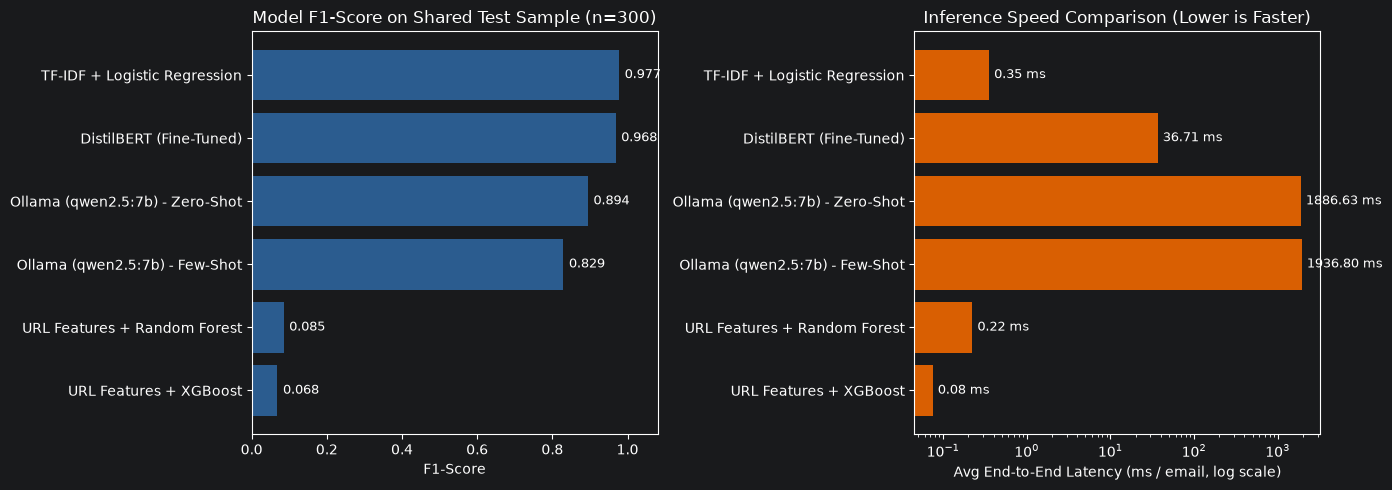

In [3]:
plot_df = sample_comp.sort_values(by="f1", ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. F1-Score comparison
axes[0].barh(plot_df["model"], plot_df["f1"], color="#2b5c8f")
axes[0].set_xlim(0, 1.08)
axes[0].set_xlabel("F1-Score")
axes[0].set_title("Model F1-Score on Shared Test Sample (n=300)")
for idx, val in enumerate(plot_df["f1"]):
    axes[0].text(val + 0.015, idx, f"{val:.3f}", va="center", fontsize=9)

# 2. End-to-End Inference Latency (log scale)
axes[1].barh(plot_df["model"], plot_df["avg_e2e_inference_ms"], color="#d95f02")
axes[1].set_xscale("log")
axes[1].set_xlabel("Avg End-to-End Latency (ms / email, log scale)")
axes[1].set_title("Inference Speed Comparison (Lower is Faster)")
for idx, val in enumerate(plot_df["avg_e2e_inference_ms"]):
    axes[1].text(val * 1.15, idx, f"{val:.2f} ms", va="center", fontsize=9)

plt.tight_layout()
plt.show()

## Preliminary Findings & Error Interpretation
* **Textual Models (`TF-IDF + LogReg` vs. `DistilBERT`):** Both models achieve strong performance on the full test set (`F1 = 0.9763` and `0.9698`, respectively). Notably, `TF-IDF + Logistic Regression` slightly outperforms `DistilBERT` while being >100x faster on CPU (`0.33 ms` vs `41.4 ms` per email in batch mode) and requiring only `0.89 MB` of storage compared to `256.1 MB`.
* **URL-Only Models (`Random Forest` / `XGBoost`):** Although precision on flagged emails is relatively high (`0.75–0.80`), overall recall remains low (`~0.055`, `F1 ≈ 0.10–0.11`). This happens because ~77% of emails in the corpus contain no explicit `http/www` URLs, forcing URL-only classifiers to default to the majority legitimate class (~62.7% baseline accuracy).
* **Next Steps:** Complete the cross-dataset generalization experiment (evaluating models trained on full bodies against the subject-only dataset and vice versa), tighten leakage grouping to exact tokenized inputs, and perform qualitative Error Analysis on misclassified emails.

In [4]:
import os
import pandas as pd

for name, folder in [("Dataset 1 (Subject-only)", "../data/processed"), ("Dataset 2 (Full-text)", "../data/processed_full")]:
    dfs = [pd.read_csv(os.path.join(folder, split)) for split in ["train.csv", "val.csv", "test.csv"]]
    full = pd.concat(dfs, ignore_index=True)
    total = len(full)
    phish = int((full["label"] == 1).sum())
    print(f"{name}: total = {total:,} | phishing = {phish:,} ({phish / total * 100:.2f}%) | legitimate = {total - phish:,} ({(total - phish) / total * 100:.2f}%)")

Dataset 1 (Subject-only): total = 130,164 | phishing = 57,939 (44.51%) | legitimate = 72,225 (55.49%)
Dataset 2 (Full-text): total = 17,488 | phishing = 6,532 (37.35%) | legitimate = 10,956 (62.65%)


## Cross-Dataset Generalization (Domain Shift Analysis)
To test how well models generalize across different email representations without retraining, we evaluate:
1. **Full-Text (DS2) → Subject-Only (DS1):** Models trained on full email bodies tested on 19,525 email subjects.
2. **Subject-Only (DS1) → Full-Text (DS2):** Models trained on email subjects tested on 2,498 full email bodies.

,direction,model,n_samples,accuracy,precision,recall,f1,tn,fp,fn,tp,avg_e2e_inference_ms
0,Train: Full-Text (DS2) -> Test: Subject-Only (...,TF-IDF + Logistic Regression,19525,0.7643,0.7157,0.7805,0.7467,8139,2695,1908,6783,0.0106
1,Train: Full-Text (DS2) -> Test: Subject-Only (...,URL Features + Random Forest,19525,0.5515,0.0541,0.0005,0.0009,10764,70,8687,4,0.0066
2,Train: Full-Text (DS2) -> Test: Subject-Only (...,URL Features + XGBoost,19525,0.5514,0.0282,0.0002,0.0005,10765,69,8689,2,0.0047
3,Train: Full-Text (DS2) -> Test: Subject-Only (...,DistilBERT (Fine-Tuned),19525,0.8122,0.7783,0.8085,0.7931,8832,2002,1664,7027,10.4503
4,Train: Subject-Only (DS1) -> Test: Full-Text (...,TF-IDF + Logistic Regression,2498,0.8223,0.6885,0.9571,0.8009,1161,404,40,893,0.3095
5,Train: Subject-Only (DS1) -> Test: Full-Text (...,URL Features + Random Forest,2498,0.6137,0.2419,0.0161,0.0302,1518,47,918,15,0.0698
6,Train: Subject-Only (DS1) -> Test: Full-Text (...,URL Features + XGBoost,2498,0.6081,0.1892,0.0150,0.0278,1505,60,919,14,0.0608


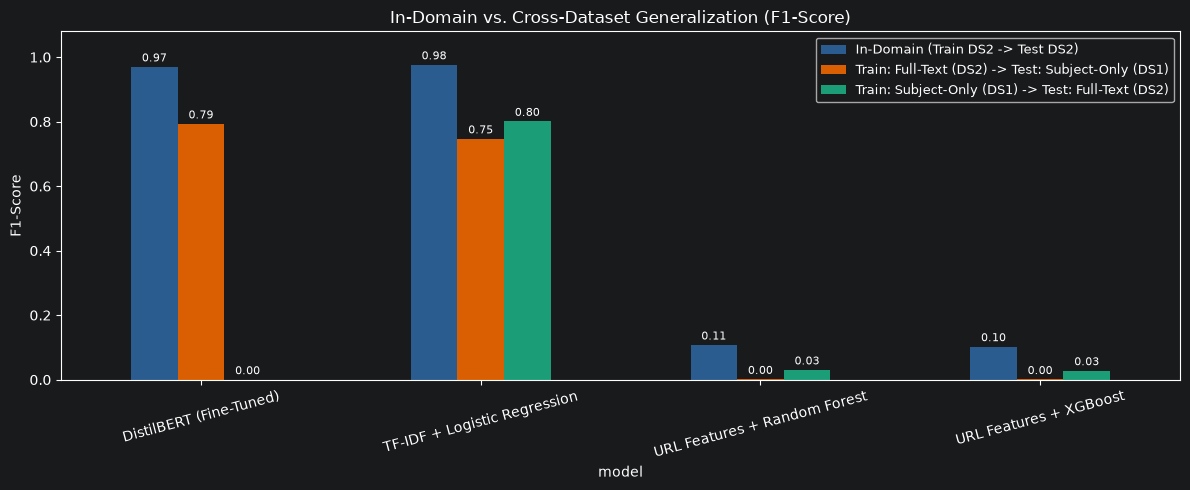

In [5]:
cross_path = os.path.join(results_dir, "cross_dataset_metrics.csv")
cross_df = pd.read_csv(cross_path)
display(cross_df)

# Compare In-Domain F1 (DS2 full_test) vs Cross-Dataset F1
in_domain = full_comp[["model", "f1"]].copy()
in_domain["setting"] = "In-Domain (Train DS2 -> Test DS2)"

cross_plot = cross_df[["model", "f1", "direction"]].rename(columns={"direction": "setting"})
comp_plot = pd.concat([in_domain, cross_plot], ignore_index=True)

pivot_df = comp_plot.pivot(index="model", columns="setting", values="f1")
ax = pivot_df.plot(kind="bar", figsize=(12, 5), rot=15, color=["#2b5c8f", "#d95f02", "#1b9e77"])
ax.set_ylim(0, 1.08)
ax.set_ylabel("F1-Score")
ax.set_title("In-Domain vs. Cross-Dataset Generalization (F1-Score)")
ax.legend(loc="upper right", fontsize=9)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", fontsize=8, padding=2)
plt.tight_layout()
plt.show()

In [7]:
import re
import pandas as pd
from IPython.display import display, HTML
from sklearn.metrics import precision_score, recall_score, f1_score

test_preds = pd.read_csv(os.path.join(results_dir, "test_predictions.csv"))
url_pattern = re.compile(r"(https?://[^\s<>\"']+|www\.[^\s<>\"']+)", re.IGNORECASE)
test_preds["has_url"] = test_preds["full_text"].astype(str).apply(lambda x: bool(url_pattern.search(x)))

# 1. Таблица качества на подвыборке писем, содержащих URL
url_subset = test_preds[test_preds["has_url"]]
n_url = len(url_subset)
pct_url = test_preds["has_url"].mean() * 100

url_rows = []
for col, name in [
    ("TF-IDF + Logistic Regression", "pred_tfidf_logreg"),
    ("DistilBERT (Fine-Tuned)", "pred_distilbert"),
    ("URL Features + XGBoost", "pred_url_xgb"),
    ("URL Features + Random Forest", "pred_url_rf"),
]:
    y_t = url_subset["label"]
    y_p = url_subset[name]
    url_rows.append({
        "Model": col,
        "Subset": f"URL-only emails (n={n_url}, {pct_url:.1f}%)",
        "Precision": round(precision_score(y_t, y_p, zero_division=0), 4),
        "Recall": round(recall_score(y_t, y_p, zero_division=0), 4),
        "F1-Score": round(f1_score(y_t, y_p, zero_division=0), 4),
    })

display(HTML("<h4>1. Diagnostic on URL-Containing Emails Only</h4>"))
display(pd.DataFrame(url_rows))

# 2. Красивые таблицы с примерами ошибок (False Positives & False Negatives)
def format_error_table(df_slice: pd.DataFrame) -> pd.DataFrame:
    out = pd.DataFrame({
        "Row ID": df_slice.index,
        "True Label": df_slice["label"].map({0: "Legitimate (0)", 1: "Phishing (1)"}),
        "DistilBERT": df_slice["pred_distilbert"],
        "TF-IDF": df_slice["pred_tfidf_logreg"],
        "Has URL": df_slice["has_url"].map({True: "Yes", False: "No"}),
        "Email Text Snippet": df_slice["full_text"].astype(str).str.slice(0, 180) + "...",
    })
    return out

fp_cases = test_preds[(test_preds["label"] == 0) & (test_preds["pred_distilbert"] == 1)].head(5)
fn_cases = test_preds[(test_preds["label"] == 1) & (test_preds["pred_distilbert"] == 0)].head(5)

pd.set_option("display.max_colwidth", 200)

display(HTML("<h4>2. Sample False Positives (Legitimate Flagged as Phishing by DistilBERT)</h4>"))
display(format_error_table(fp_cases).style.hide(axis="index").set_properties(**{"text-align": "left"}))

display(HTML("<h4>3. Sample False Negatives (Phishing Missed by DistilBERT)</h4>"))
display(format_error_table(fn_cases).style.hide(axis="index").set_properties(**{"text-align": "left"}))

,Model,Subset,Precision,Recall,F1-Score
0,TF-IDF + Logistic Regression,"URL-only emails (n=592, 23.7%)",0.9706,0.9612,0.9659
1,DistilBERT (Fine-Tuned),"URL-only emails (n=592, 23.7%)",0.9174,0.9709,0.9434
2,URL Features + XGBoost,"URL-only emails (n=592, 23.7%)",0.7969,0.4951,0.6108
3,URL Features + Random Forest,"URL-only emails (n=592, 23.7%)",0.7500,0.5243,0.6171


Row ID,True Label,DistilBERT,TF-IDF,Has URL,Email Text Snippet
43,Legitimate (0),1,0,Yes,"Hi,I believe you get more value for money by separating the mobile phone from the PDA.As expressed by power users on Open, a combination like a EUR 160 Nokia 6310i talking to a EUR..."
165,Legitimate (0),1,0,No,moneycentral : 6 routes to retire rich ecial = msn...
643,Legitimate (0),1,0,No,dates / info just wanted to keep you all posted on the latest and greatest . . . . . launch dates : bandwidth may 1 us pcg brazil ( power ) july 1 us pcg japan may 17 us pcg austri...
664,Legitimate (0),1,0,Yes,Interesting ebay item......(and no it wasnt me even though the spellingis oddly familar)http://cgi.ebay.com/aw-cgi/eBayISAPI.dll?MfcISAPICommand=ViewItem&item=1764085998...
811,Legitimate (0),1,1,Yes,"You are receiving this email because you signed up to receive one of our free reports. If you would prefer not to receive messages of this type, please unsubscribe by following the..."


Row ID,True Label,DistilBERT,TF-IDF,Has URL,Email Text Snippet
48,Phishing (1),0,1,Yes,"Hallo,Wir haben uns schon ziemlich lange nicht mehr gesehen, a ich ja nur noh Zeit fÃ¼r meine Freundin hatte. DAMIT ist jetzt SchluÃŸ.Alex hat mich sitzen lassen. Du erhÃ¤lst diese..."
347,Phishing (1),0,1,No,"your application is below . expires july 27 . your application for the grant is below . remember , because of the type of grant this is , you will never need to repay ! > > time is..."
450,Phishing (1),0,1,No,"attention : latest updates . download any latest software now ! http : / / apologist . 405 ajr . com / marian , with regards ...."
452,Phishing (1),0,0,No,re : re : re : your document please read the attached file ....
536,Phishing (1),0,1,No,4623...


## Cross-Dataset & Error Analysis Conclusions
1. **Superior Domain Generalization of DistilBERT:** While `TF-IDF + LogReg` slightly edges out `DistilBERT` within the same dataset (`0.976` vs `0.970`), `DistilBERT` outperforms `TF-IDF` by **+4.64% F1** (`0.7931` vs `0.7467`) when transferring from full email bodies to unseen email subjects. Contextual embeddings capture semantic phishing intent even when exact lexical n-grams change.
2. **Asymmetric Transfer (Subjects → Full Bodies):** Models trained on short subjects achieve very high recall (`95.7%` for TF-IDF) on full bodies, catching almost all phishing emails (`only 40 FN`), but suffer from increased false positives (`404 FP`, `Precision = 0.689`) because longer legitimate texts contain more trigger words.
3. **Limitations of Pure URL Features:** Even when evaluated strictly on the subset of emails containing explicit URLs, lexical URL features alone lag far behind full-text semantic models, confirming that phishing detection requires combining URL structure with message context.

## Qualitative Error Analysis Summary
1. **URL-Subset Diagnostic:** Evaluating `URL XGBoost` exclusively on the 592 test emails containing URLs (23.7%) raises its F1-score from `0.102` to `0.611` (`Precision = 0.797`), confirming that low overall recall stems from dataset sparsity (76.3% URL-free emails) rather than feature extraction failure.
2. **False Positives (Legitimate → Phishing):** Driven primarily by legitimate marketing/unsubscribe footers (Row 811, flagged by both DistilBERT and TF-IDF), complex query parameters in benign e-commerce URLs such as eBay (Row 664), and financial/pricing vocabulary in normal discussions (Rows 43, 165).
3. **False Negatives (Phishing → Legitimate):**
   * *Monolingual Limitation:* `distilbert-base-uncased` missed a German-language phishing email with encoding artifacts (Row 48), pointing to multilingual transformers (`XLM-RoBERTa`) as a natural extension.
   * *Whitespace URL Obfuscation:* Spaced URLs like `http : / / apologist . 405 ajr . com /` (Row 450) bypassed both the URL regex and DistilBERT, though TF-IDF caught the surrounding download lure.
   * *Context-Starved / Attachment Lures:* Minimalist messages referring to attachments without links or body text (Rows 452, 536) cannot be detected purely from plain-text bodies.